<style>
  .hrnova-cover {
    padding: 34px 38px; border-radius: 18px;
    background: linear-gradient(135deg, #102a43 0%, #1f6f8b 58%, #62b6cb 100%);
    color: white; box-shadow: 0 10px 30px rgba(16,42,67,.18); margin-bottom: 18px;
  }
  .hrnova-cover h1 { margin: 0 0 8px 0; font-size: 38px; }
  .hrnova-cover p { margin: 6px 0; font-size: 16px; opacity: .94; }
  .section-title {
    margin: 26px 0 14px; padding: 18px 22px; border-left: 7px solid #2a9d8f;
    border-radius: 10px; background: #eef8f7; color: #16324f;
  }
  .section-title h2 { margin: 0; }
  .info-card {
    padding: 14px 18px; border-radius: 10px; background: #f7fafc;
    border: 1px solid #d9e2ec; margin: 10px 0 16px;
  }
  .decision-card {
    padding: 14px 18px; border-radius: 10px; background: #fff8e8;
    border-left: 6px solid #e9c46a; margin: 10px 0 16px;
  }
  .success-card {
    padding: 14px 18px; border-radius: 10px; background: #edf8f0;
    border-left: 6px solid #43aa8b; margin: 10px 0 16px;
  }
  .criterion { color: #1f6f8b; font-weight: 700; }
  table { font-size: 14px; }
</style>

<div class="hrnova-cover">
  <h1>HRNova — Prédiction du départ des salariés</h1>
  <p><b>Projet 4 · TechNova Partners</b></p>
  <p>Analyse exploratoire, nettoyage, préparation, modélisation et interprétabilité</p>
  <p style="font-size:13px; margin-top:16px;">Cible : <code>a_quitte_l_entreprise</code> · Classification binaire</p>
</div>


<div class="info-card">
  <b>Objectif métier.</b> Identifier les facteurs associés au turnover et construire un modèle capable
  de repérer les salariés présentant un risque de départ, sans oublier que la classe « départ » est minoritaire.
</div>

### Fil conducteur

1. Charger et contrôler les trois sources de données.
2. Nettoyer, fusionner et analyser les deux populations.
3. Transformer les colonnes et créer de nouvelles variables.
4. Préparer un jeu numérique compatible avec les modèles.
5. Comparer un modèle étalon, un modèle linéaire et un modèle non linéaire.
6. Optimiser le Random Forest, calibrer ses probabilités et justifier le seuil.
7. Interpréter le modèle globalement et localement avec SHAP.

<div class="success-card">
  <b>Principe de reproductibilité.</b> Toutes les dépendances utilisées ici sont déclarées dans
  <code>pyproject.toml</code>. Depuis la racine du projet : <code>pip install -e .</code>
</div>


<div class="section-title"><h2>0 · Environnement et reproductibilité</h2></div>

Le notebook attend l'arborescence suivante :

```text
projet/
├── pyproject.toml
├── dataScientistTechNova2.ipynb
└── Data/
    ├── extrait_eval.csv
    ├── extrait_sirh.csv
    └── extrait_sondage.csv
```

Les graines aléatoires sont fixées à `42`. Les transformations apprises par un modèle
(notamment le scaling) sont placées dans une `Pipeline` afin d'être réapprises dans chaque fold.


In [39]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import shap
from IPython import get_ipython
from IPython.display import display
from lightgbm import LGBMClassifier
from ydata_profiling import ProfileReport

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "a_quitte_l_entreprise"

np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", palette="deep")

# Force l'intégration des figures Matplotlib et SHAP dans le notebook.
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")


In [40]:
DATA_DIR = Path("Data")
FICHIERS = {
    "evaluations": DATA_DIR / "extrait_eval.csv",
    "sirh": DATA_DIR / "extrait_sirh.csv",
    "sondage": DATA_DIR / "extrait_sondage.csv",
}

eval_extract = pd.read_csv(FICHIERS["evaluations"])
sirh_extract = pd.read_csv(FICHIERS["sirh"])
sondage_extract = pd.read_csv(FICHIERS["sondage"])


<div class="section-title"><h2>1 · Analyse exploratoire et qualité des données</h2></div>



In [41]:
def resume_qualite(nom: str, df: pd.DataFrame) -> dict:
    '''Retourne les indicateurs élémentaires de qualité d'un DataFrame.'''
    return {
        "jeu_de_donnees": nom,
        "lignes": df.shape[0],
        "colonnes": df.shape[1],
        "valeurs_manquantes": int(df.isna().sum().sum()),
        "doublons_exacts": int(df.duplicated().sum()),
    }

sources = {
    "Évaluations": eval_extract,
    "SIRH": sirh_extract,
    "Sondage": sondage_extract,
}

synthese_qualite = pd.DataFrame(
    [resume_qualite(nom, df) for nom, df in sources.items()]
).set_index("jeu_de_donnees")

display(synthese_qualite)


,lignes,colonnes,valeurs_manquantes,doublons_exacts
jeu_de_donnees,,,,
Évaluations,1470,10,0,0
SIRH,1470,12,0,0
Sondage,1470,12,0,0


In [42]:
def table_completude(df: pd.DataFrame) -> pd.DataFrame:
    '''Détaille le volume et le taux de valeurs manquantes par colonne.'''
    return (
        pd.DataFrame({
            "type": df.dtypes.astype(str),
            "valeurs_manquantes": df.isna().sum(),
            "taux_manquant_pct": df.isna().mean().mul(100).round(2),
            "valeurs_uniques": df.nunique(dropna=False),
        })
        .sort_values(["valeurs_manquantes", "valeurs_uniques"], ascending=[False, True])
    )


for nom, df in sources.items():
    print(f"\n{nom} — aperçu")
    display(df.head())
    display(table_completude(df))



Évaluations — aperçu


,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


,type,valeurs_manquantes,taux_manquant_pct,valeurs_uniques
note_evaluation_actuelle,int64,0,0.0,2
heure_supplementaires,object,0,0.0,2
satisfaction_employee_environnement,int64,0,0.0,4
note_evaluation_precedente,int64,0,0.0,4
satisfaction_employee_nature_travail,int64,0,0.0,4
satisfaction_employee_equipe,int64,0,0.0,4
satisfaction_employee_equilibre_pro_perso,int64,0,0.0,4
niveau_hierarchique_poste,int64,0,0.0,5
augementation_salaire_precedente,object,0,0.0,15
eval_number,object,0,0.0,1470



SIRH — aperçu


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


,type,valeurs_manquantes,taux_manquant_pct,valeurs_uniques
nombre_heures_travailless,int64,0,0.0,1
genre,object,0,0.0,2
statut_marital,object,0,0.0,3
departement,object,0,0.0,3
poste,object,0,0.0,9
nombre_experiences_precedentes,int64,0,0.0,10
annees_dans_le_poste_actuel,int64,0,0.0,19
annees_dans_l_entreprise,int64,0,0.0,37
annee_experience_totale,int64,0,0.0,40
age,int64,0,0.0,43



Sondage — aperçu


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


,type,valeurs_manquantes,taux_manquant_pct,valeurs_uniques
nombre_employee_sous_responsabilite,int64,0,0.0,1
ayant_enfants,object,0,0.0,1
a_quitte_l_entreprise,object,0,0.0,2
frequence_deplacement,object,0,0.0,3
nombre_participation_pee,int64,0,0.0,4
niveau_education,int64,0,0.0,5
domaine_etude,object,0,0.0,6
nb_formations_suivies,int64,0,0.0,7
annees_depuis_la_derniere_promotion,int64,0,0.0,16
annes_sous_responsable_actuel,int64,0,0.0,18


In [43]:
population_classes_brute = (
    sondage_extract[TARGET]
    .value_counts(dropna=False)
    .rename_axis("classe")
    .to_frame("effectif")
)
population_classes_brute["proportion_pct"] = (
    population_classes_brute["effectif"]
    .div(population_classes_brute["effectif"].sum())
    .mul(100)
    .round(2)
)

display(population_classes_brute)

fig = px.bar(
    population_classes_brute.reset_index(),
    x="classe",
    y="effectif",
    color="classe",
    text="effectif",
    title="Nombre d'individus dans chaque classe",
    labels={"classe": "A quitté l'entreprise", "effectif": "Nombre de salariés"},
    color_discrete_map={"Non": "#2a9d8f", "Oui": "#e76f51"},
)
fig.update_layout(showlegend=False, template="plotly_white")
fig.show()


,effectif,proportion_pct
classe,,
Non,1233,83.88
Oui,237,16.12


<div class="info-card">
  Le jeu est déséquilibré : la classe « départ » est minoritaire.
  Cette observation justifie l'utilisation de la statification, l'usage de <code>class_weight="balanced"</code>
  et ensuite sur le réajustement du seuil
</div>


In [44]:
# Optionnel : rapports HTML détaillés. Le bouton évite de ralentir chaque réexécution.
GENERER_RAPPORTS_PROFILING = True

if GENERER_RAPPORTS_PROFILING:
    for nom, df in sources.items():
        rapport = ProfileReport(df, title=f"Profiling Report — {nom}", minimal=True)
        rapport.to_file(f"profiling_{nom.lower()}.html")


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:00<00:00, 69788.75it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

...

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 12/12 [00:00<00:00, 118987.35it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

<div class="section-title"><h2>2 · Fusion et nettoyage automatisé</h2></div>

Relations entre les sources :

- `sondage.code_sondage` ↔ `sirh.id_employee`
- `sondage.code_sondage` ↔ `eval.eval_number`

La première jointure reste une jointure gauche afin de ne pas perdre les salariés du sondage.
La seconde conserve la logique initiale avec une jointure interne sur les évaluations.


In [45]:
def extraire_numero_evaluation(valeur):
    '''Extrait l'identifiant numérique d'une valeur telle que EVAL-123.'''
    if pd.isna(valeur):
        return pd.NA
    resultat = re.search(r"(\d+)", str(valeur))
    return int(resultat.group(1)) if resultat else pd.NA


def nettoyer_pourcentage(valeur):
    '''Transforme une chaîne telle que 18 % en nombre flottant 18.0.'''
    if pd.isna(valeur):
        return np.nan
    return float(str(valeur).replace("%", "").strip())


# Transformation 1 avec .apply() : identifiant d'évaluation exploitable.
eval_extract = eval_extract.copy()
eval_extract["eval_number"] = (
    eval_extract["eval_number"]
    .apply(extraire_numero_evaluation)
    .astype("Int64")
)


In [46]:
df_merge = sondage_extract.merge(
    sirh_extract,
    left_on="code_sondage",
    right_on="id_employee",
    how="left",
)

df_merge = df_merge.merge(
    eval_extract,
    left_on="code_sondage",
    right_on="eval_number",
    how="inner",
)

df_merge = df_merge.drop(columns=["code_sondage", "eval_number", "id_employee"])

# Transformation 2 avec .apply() : pourcentage converti en variable quantitative.
df_merge["augementation_salaire_precedente"] = (
    df_merge["augementation_salaire_precedente"]
    .apply(nettoyer_pourcentage)
)

print(f"Dimensions après fusion : {df_merge.shape}")
display(df_merge.head())


Dimensions après fusion : (1470, 31)


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,Oui,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,2,3,2,4,1,1,3,Oui,11.0
1,Non,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,3,2,2,2,4,3,4,Non,23.0
2,Oui,0,3,1,2,2,Autre,Y,Occasionnel,0,0,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,4,2,1,3,2,3,3,Oui,15.0
3,Non,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,4,3,1,3,3,3,3,Oui,11.0
4,Non,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,1,3,1,2,4,3,3,Non,12.0


In [47]:
# Label Encoding de la cible : LabelEncoder classe naturellement Non=0 et Oui=1.
encodeur_cible = LabelEncoder()
df_merge[TARGET] = encodeur_cible.fit_transform(df_merge[TARGET])
correspondance_cible = dict(
    zip(encodeur_cible.classes_, encodeur_cible.transform(encodeur_cible.classes_))
)

assert correspondance_cible.get("Non") == 0 and correspondance_cible.get("Oui") == 1
print("Encodage de la cible :", correspondance_cible)
display(df_merge[TARGET].value_counts().sort_index().rename("effectif"))


Encodage de la cible : {'Non': np.int64(0), 'Oui': np.int64(1)}


a_quitte_l_entreprise
0    1233
1     237
Name: effectif, dtype: int64

<div class="section-title"><h2>3 · Comparaison visuelle des deux populations</h2></div>

<span class="criterion">CE1 — Visualisations avec la cible.</span>
L'histogramme, le boxplot et le scatterplot distinguent explicitement les salariés restés et partis.


In [48]:
df_visualisation = df_merge.assign(
    classe_cible=df_merge[TARGET].map({0: "Resté", 1: "Quitté"})
)

fig = px.histogram(
    df_visualisation,
    x="annees_depuis_la_derniere_promotion",
    color="classe_cible",
    barmode="overlay",
    opacity=0.65,
    nbins=20,
    marginal="rug",
    title="Histogramme — ancienneté de la dernière promotion selon la cible",
    labels={
        "annees_depuis_la_derniere_promotion": "Années depuis la dernière promotion",
        "classe_cible": "Population",
    },
    color_discrete_map={"Resté": "#2a9d8f", "Quitté": "#e76f51"},
)
fig.update_layout(template="plotly_white")
fig.show()


In [49]:
fig = px.box(
    df_visualisation,
    x="classe_cible",
    y="revenu_mensuel",
    color="classe_cible",
    points="outliers",
    title="Boxplot — revenu mensuel selon la cible",
    labels={
        "classe_cible": "Population",
        "revenu_mensuel": "Revenu mensuel",
    },
    color_discrete_map={"Resté": "#2a9d8f", "Quitté": "#e76f51"},
)
fig.update_layout(showlegend=False, template="plotly_white")
fig.show()


In [50]:
fig = px.scatter(
    df_visualisation,
    x="age",
    y="revenu_mensuel",
    color="classe_cible",
    opacity=0.65,
    hover_data=["poste", "departement", "annees_dans_l_entreprise"],
    title="Scatterplot — âge et revenu mensuel selon la cible",
    labels={
        "age": "Âge",
        "revenu_mensuel": "Revenu mensuel",
        "classe_cible": "Population",
    },
    color_discrete_map={"Resté": "#2a9d8f", "Quitté": "#e76f51"},
)
fig.update_layout(template="plotly_white")
fig.show()


In [51]:
taux_depart_departement = (
    df_merge.groupby("departement")[TARGET]
    .agg(effectif="size", taux_depart="mean")
    .assign(taux_depart_pct=lambda table: table["taux_depart"].mul(100))
    .sort_values("taux_depart_pct", ascending=False)
    .reset_index()
)

fig = px.bar(
    taux_depart_departement,
    x="departement",
    y="taux_depart_pct",
    color="taux_depart_pct",
    text="effectif",
    title="Taux de départ par département (texte = effectif)",
    labels={"departement": "Département", "taux_depart_pct": "Taux de départ (%)"},
    color_continuous_scale="Tealrose",
)
fig.update_layout(template="plotly_white")
fig.show()


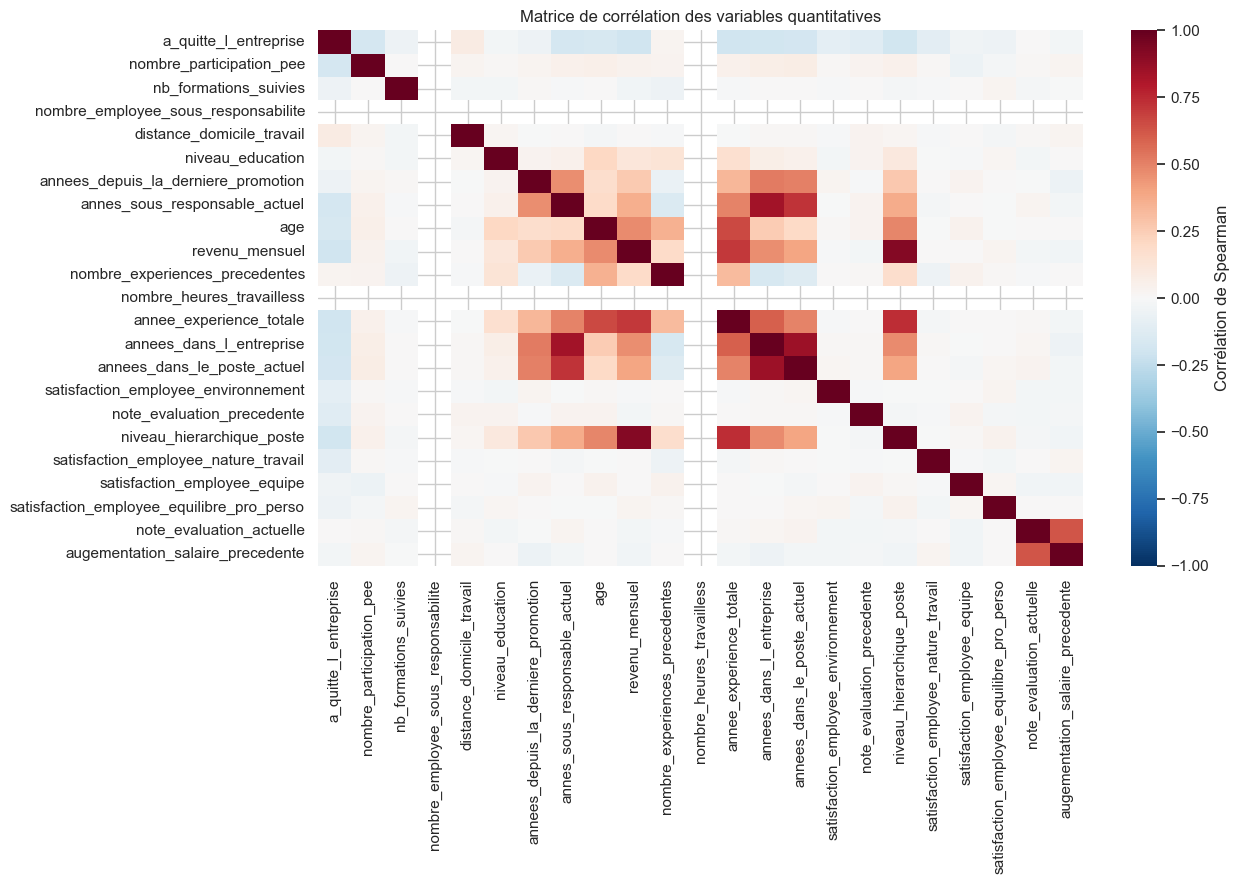

,correlation_avec_la_cible
annee_experience_totale,-0.199002
revenu_mensuel,-0.198305
annees_dans_l_entreprise,-0.190419
niveau_hierarchique_poste,-0.190370
annees_dans_le_poste_actuel,-0.180623
annes_sous_responsable_actuel,-0.175355
nombre_participation_pee,-0.172296
age,-0.171214
note_evaluation_precedente,-0.119496
satisfaction_employee_nature_travail,-0.102948


In [52]:
correlation_initiale = df_merge.corr(numeric_only=True, method="spearman")

plt.figure(figsize=(13, 9))
sns.heatmap(
    correlation_initiale,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=False,
    cbar_kws={"label": "Corrélation de Spearman"},
)
plt.title("Matrice de corrélation des variables quantitatives")
plt.tight_layout()
plt.show()

correlations_cible = (
    correlation_initiale[TARGET]
    .drop(TARGET)
    .sort_values(key=np.abs, ascending=False)
    .rename("correlation_avec_la_cible")
    .to_frame()
)
display(correlations_cible.head(15))


<div class="section-title"><h2>4 · Transformations et feature engineering</h2></div>

<span class="criterion">CE2/CE3 — Transformation et compatibilité.</span>
La variable binaire `heure_supplementaires` est encodée avec `LabelEncoder`, la fréquence des
déplacements conserve son ordre métier, puis les variables nominales sont traitées avec `OneHotEncoder`.


In [53]:
# Label Encoding adapté à la variable réellement binaire.
encodeur_heures_supplementaires = LabelEncoder()
df_merge["heure_supplementaires"] = (
    encodeur_heures_supplementaires.fit_transform(df_merge["heure_supplementaires"])
)
correspondance_heures_supplementaires = dict(zip(
    encodeur_heures_supplementaires.classes_,
    encodeur_heures_supplementaires.transform(
        encodeur_heures_supplementaires.classes_
    ),
))

# La logique métier Y=1 / N=0 est conservée. Dans ce fichier, la colonne est constante (Y).
df_merge["ayant_enfants"] = df_merge["ayant_enfants"].map({"Y": 1, "N": 0})

# Encodage ordinal : l'ordre 0 < 1 < 2 a une signification métier.
ordre_deplacements = {"Aucun": 0, "Occasionnel": 1, "Frequent": 2}
df_merge["frequence_deplacement"] = (
    df_merge["frequence_deplacement"].map(ordre_deplacements)
)

# Reprise des indicateurs binaires du notebook initial.
df_merge["genreIsMale"] = df_merge["genre"].map({"M": 1, "F": 0})
df_merge["IsMarried"] = df_merge["statut_marital"].map({
    "Marié(e)": 1, "Célibataire": 0, "Divorcé(e)": 0,
})
df_merge["IsSingle"] = df_merge["statut_marital"].map({
    "Marié(e)": 0, "Célibataire": 1, "Divorcé(e)": 1,
})

display(pd.Series(
    correspondance_heures_supplementaires,
    name="Encodage de heure_supplementaires",
))
assert df_merge[["frequence_deplacement", "genreIsMale", "IsMarried", "IsSingle"]].isna().sum().sum() == 0


Non    0
Oui    1
Name: Encodage de heure_supplementaires, dtype: int64

In [54]:
# Feature 1 — ratio simple revenu / âge (testée puis écartée plus bas).
df_merge["revenu_par_age"] = df_merge["revenu_mensuel"] / df_merge["age"]

# Features 2 et 3 — indicateurs de rémunération relative.
revenu_median = df_merge["revenu_mensuel"].median()
df_merge["jeune_sous_paye"] = (
    (df_merge["age"] < 30) & (df_merge["revenu_mensuel"] < revenu_median)
).astype(int)
df_merge["sous_paye_moyenne"] = (
    df_merge["revenu_mensuel"] < revenu_median
).astype(int)

# Feature 4 — salaire relatif au niveau d'éducation et à l'ancienneté.
df_merge["groupe_anciennete"] = pd.cut(
    df_merge["annees_dans_l_entreprise"],
    bins=[0, 2, 5, 10, 20, 50],
    labels=["0-2", "3-5", "6-10", "11-20", "20+"],
    include_lowest=True,
)
salaire_median_groupe = (
    df_merge.groupby(
        ["niveau_education", "groupe_anciennete"], observed=False
    )["revenu_mensuel"]
    .transform("median")
)
df_merge["ratio_salaire_edu_anciennete"] = (
    df_merge["revenu_mensuel"] / salaire_median_groupe
)
df_merge["fortement_sous_paye"] = (
    df_merge["ratio_salaire_edu_anciennete"] < 0.85
).astype(int)

# Feature 5 — synthèse des quatre dimensions de satisfaction.
colonnes_satisfaction = [
    "satisfaction_employee_environnement",
    "satisfaction_employee_nature_travail",
    "satisfaction_employee_equipe",
    "satisfaction_employee_equilibre_pro_perso",
]
df_merge["satisfaction_globale"] = df_merge[colonnes_satisfaction].mean(axis=1)

nouvelles_features = [
    "revenu_par_age",
    "jeune_sous_paye",
    "sous_paye_moyenne",
    "ratio_salaire_edu_anciennete",
    "fortement_sous_paye",
    "satisfaction_globale",
]
display(df_merge[nouvelles_features].describe().T)


,count,mean,std,min,25%,50%,75%,max
revenu_par_age,1470.0,170.942819,101.848349,36.033333,93.210728,140.970238,223.465903,556.000000
jeune_sous_paye,1470.0,0.182313,0.386234,0.000000,0.000000,0.000000,0.000000,1.000000
sous_paye_moyenne,1470.0,0.500000,0.500170,0.000000,0.000000,0.500000,1.000000,1.000000
ratio_salaire_edu_anciennete,1470.0,1.247757,0.904577,0.231798,0.706201,1.000000,1.442035,7.026899
fortement_sous_paye,1470.0,0.359864,0.480124,0.000000,0.000000,0.000000,1.000000,1.000000
satisfaction_globale,1470.0,2.730952,0.505815,1.000000,2.500000,2.750000,3.000000,4.000000


### Élimination des variables quantitatives redondantes

La matrice ci-dessous repère les paires fortement corrélées. La sélection finale reprend ensuite
les décisions du notebook initial :

- `fortement_sous_paye` est une discrétisation redondante du ratio de salaire ;
- les quatre satisfactions sources sont remplacées par `satisfaction_globale` ;
- `groupe_anciennete` ne sert qu'à construire le ratio ;
- `revenu_par_age` est écartée, car l'expérimentation initiale dégradait les performances.


In [55]:
correlation_quantitative = df_merge.corr(numeric_only=True).abs()
triangle_superieur = correlation_quantitative.where(
    np.triu(np.ones(correlation_quantitative.shape), k=1).astype(bool)
)

paires_fortement_correlees = (
    triangle_superieur.stack()
    .rename("correlation_absolue")
    .loc[lambda serie: serie >= 0.80]
    .sort_values(ascending=False)
    .rename_axis(["variable_1", "variable_2"])
    .reset_index()
)
display(paires_fortement_correlees)

features_eliminees_redondance = [
    "revenu_par_age",
    "fortement_sous_paye",
    *colonnes_satisfaction,
]
autres_colonnes_exclues = ["groupe_anciennete"]

df_selection = df_merge.drop(
    columns=features_eliminees_redondance + autres_colonnes_exclues
).copy()

print("Variables éliminées pour redondance :", features_eliminees_redondance)
print("Autres variables exclues après expérimentation :", autres_colonnes_exclues)
print("Dimensions après sélection :", df_selection.shape)


,variable_1,variable_2,correlation_absolue
0,IsMarried,IsSingle,1.000000
1,revenu_mensuel,niveau_hierarchique_poste,0.950300
2,revenu_mensuel,revenu_par_age,0.932472
3,niveau_hierarchique_poste,revenu_par_age,0.877710


Variables éliminées pour redondance : ['revenu_par_age', 'fortement_sous_paye', 'satisfaction_employee_environnement', 'satisfaction_employee_nature_travail', 'satisfaction_employee_equipe', 'satisfaction_employee_equilibre_pro_perso']
Autres variables exclues après expérimentation : ['groupe_anciennete']
Dimensions après sélection : (1470, 34)


In [56]:
# One-Hot Encoding des variables nominales sans ordre naturel.
colonnes_one_hot = ["domaine_etude", "departement", "poste"]
one_hot_encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False,
    dtype=int,
)

matrice_encodee = one_hot_encoder.fit_transform(df_selection[colonnes_one_hot])
noms_colonnes_encodees = one_hot_encoder.get_feature_names_out(colonnes_one_hot)
df_one_hot = pd.DataFrame(
    matrice_encodee,
    columns=noms_colonnes_encodees,
    index=df_selection.index,
)

df_model = pd.concat(
    [
        df_selection.drop(
            columns=colonnes_one_hot + ["genre", "statut_marital"]
        ),
        df_one_hot,
    ],
    axis=1,
)

colonnes_non_numeriques = df_model.select_dtypes(exclude="number").columns.tolist()
assert not colonnes_non_numeriques, f"Colonnes non numériques restantes : {colonnes_non_numeriques}"
assert df_model.isna().sum().sum() == 0

print(f"Jeu final : {df_model.shape[0]} salariés et {df_model.shape[1] - 1} features")
display(df_model.head())


Jeu final : 1470 salariés et 43 features


,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,age,revenu_mensuel,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,note_evaluation_precedente,niveau_hierarchique_poste,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente,genreIsMale,IsMarried,IsSingle,jeune_sous_paye,sous_paye_moyenne,ratio_salaire_edu_anciennete,satisfaction_globale,domaine_etude_Entrepreunariat,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Ressources Humaines,domaine_etude_Transformation Digitale,departement_Consulting,departement_Ressources Humaines,poste_Cadre Commercial,poste_Consultant,poste_Directeur Technique,poste_Manager,poste_Représentant Commercial,poste_Ressources Humaines,poste_Senior Manager,poste_Tech Lead
0,1,0,0,1,1,2,1,1,0,5,41,5993,8,80,8,6,4,3,2,3,1,11.0,0,0,1,0,0,1.077684,2.00,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0
1,0,1,3,1,8,1,1,2,1,7,49,5130,1,80,10,10,7,2,2,4,0,23.0,1,1,0,0,0,1.013133,3.00,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0
2,1,0,3,1,2,2,1,1,0,0,37,2090,6,80,7,0,0,2,1,3,1,15.0,1,0,1,0,1,0.691595,3.00,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0
3,0,0,3,1,3,4,1,2,3,0,33,2909,1,80,8,8,7,3,1,3,1,11.0,0,1,0,0,1,0.530694,3.25,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0
4,0,1,3,1,2,1,1,1,2,2,27,3468,9,80,6,2,2,3,1,3,0,12.0,1,1,0,1,1,1.324170,2.50,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0


<div class="section-title"><h2>5 · Préparation des données pour la modélisation</h2></div>

<div class="decision-card">
  <b>Choix de scaling.</b> La régression logistique est sensible à l'échelle : elle utilise
  <code>StandardScaler</code> dans une pipeline. Le Random Forest et le DummyClassifier reposent
  sur des règles ou des coupures et ne nécessitent pas de scaling. Le scaler est appris uniquement
  sur chaque fold d'entraînement, ce qui évite une fuite de données.
</div>


In [57]:
X = df_model.drop(columns=TARGET)
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

repartitions = pd.concat(
    {
        "train": y_train.value_counts(normalize=True).sort_index(),
        "test": y_test.value_counts(normalize=True).sort_index(),
    },
    axis=1,
).rename(index={0: "Resté", 1: "Quitté"})

print(f"Train : {X_train.shape} | Test : {X_test.shape}")
display(repartitions)

cv_stratifiee = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)


Train : (1176, 43) | Test : (294, 43)


,train,test
a_quitte_l_entreprise,,
Resté,0.838435,0.840136
Quitté,0.161565,0.159864


<div class="section-title"><h2>6 · Entraînement et validation croisée</h2></div>


- **DummyClassifier** : modèle basique ;
- **Régression logistique** : modèle linéaire avec scaling ;
- **Random Forest** : modèle non linéaire sans scaling.

Les moyennes **et les écarts-types** sont calculés sur cinq folds stratifiés.


In [58]:
modeles = {
    "DummyClassifier": DummyClassifier(
        strategy="stratified",
        random_state=RANDOM_STATE,
    ),
    "LogisticRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            solver="liblinear",
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE,
        )),
    ]),
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}


In [59]:
lignes_cv = []
scores_cv = {}

for nom, modele in modeles.items():
    scores = cross_validate(
        estimator=modele,
        X=X_train,
        y=y_train,
        cv=cv_stratifiee,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )
    scores_cv[nom] = scores

    ligne = {"modele": nom}
    for metrique in scoring:
        valeurs = scores[f"test_{metrique}"]
        ligne[f"{metrique}_moyenne"] = valeurs.mean()
        ligne[f"{metrique}_ecart_type"] = valeurs.std()
    lignes_cv.append(ligne)

resultats_cv = (
    pd.DataFrame(lignes_cv)
    .set_index("modele")
    .sort_values("f1_moyenne", ascending=False)
)
display(resultats_cv.round(4))


,accuracy_moyenne,accuracy_ecart_type,precision_moyenne,precision_ecart_type,recall_moyenne,recall_ecart_type,f1_moyenne,f1_ecart_type,roc_auc_moyenne,roc_auc_ecart_type
modele,,,,,,,,,,
LogisticRegression,0.7576,0.0362,0.3786,0.0357,0.7368,0.0781,0.4968,0.0280,0.8279,0.0334
RandomForest,0.8656,0.0198,0.7151,0.1685,0.3053,0.0858,0.4189,0.0967,0.8024,0.0340
DummyClassifier,0.7406,0.0093,0.1714,0.0313,0.1579,0.0288,0.1644,0.0300,0.5054,0.0172


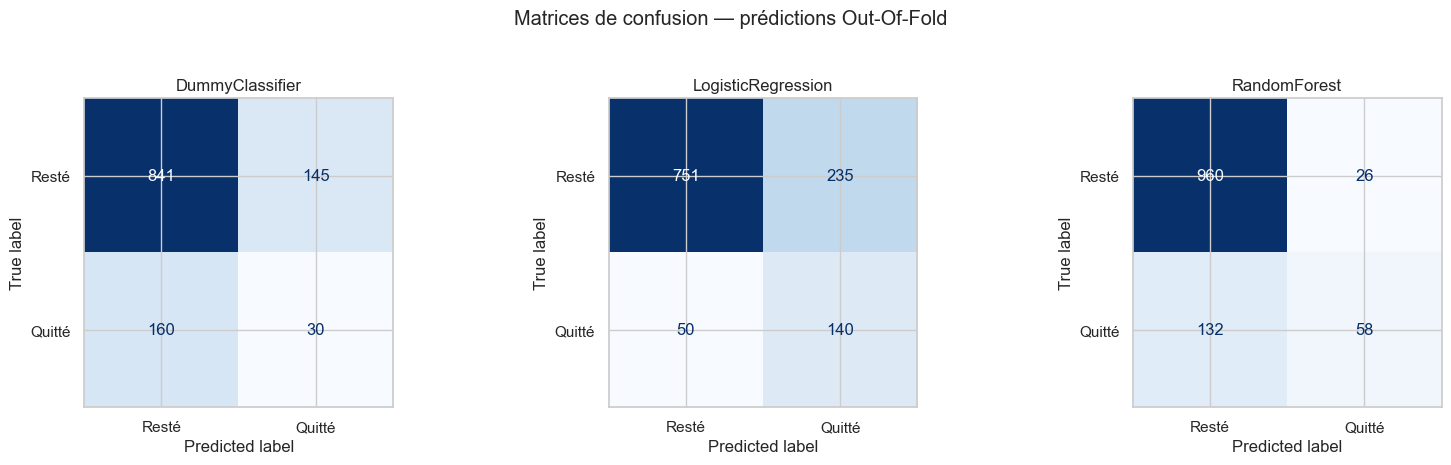

              precision    recall  f1-score   support

       Resté       0.88      0.97      0.92       986
      Quitté       0.69      0.31      0.42       190

    accuracy                           0.87      1176
   macro avg       0.78      0.64      0.67      1176
weighted avg       0.85      0.87      0.84      1176

              precision    recall  f1-score   support

       Resté       0.94      0.76      0.84       986
      Quitté       0.37      0.74      0.50       190

    accuracy                           0.76      1176
   macro avg       0.66      0.75      0.67      1176
weighted avg       0.85      0.76      0.78      1176



In [60]:
predictions_oof = {}
fig, axes = plt.subplots(1, len(modeles), figsize=(16, 4.5))

for axe, (nom, modele) in zip(axes, modeles.items()):
    y_pred_oof = cross_val_predict(
        modele,
        X_train,
        y_train,
        cv=cv_stratifiee,
        method="predict",
        n_jobs=-1,
    )
    predictions_oof[nom] = y_pred_oof
    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred_oof,
        display_labels=["Resté", "Quitté"],
        cmap="Blues",
        colorbar=False,
        ax=axe,
    )
    axe.set_title(nom)

plt.suptitle("Matrices de confusion — prédictions Out-Of-Fold", y=1.03)
plt.tight_layout()
plt.show()

print(classification_report(
    y_train,
    predictions_oof["RandomForest"],
    target_names=["Resté", "Quitté"],
    zero_division=0,
))

print(classification_report(
    y_train,
    predictions_oof["LogisticRegression"],
    target_names=["Resté", "Quitté"],
    zero_division=0,
))



<div class="section-title"><h2>7 · Fine-tuning du Random Forest</h2></div>

La grille explore **quatre hyperparamètres** : nombre d'arbres, profondeur maximale,
nombre minimal d'observations pour scinder un nœud et nombre minimal d'observations par feuille.
Le score optimisé est le F1 de la classe minoritaire.


In [61]:
rf_a_optimiser = RandomForestClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

grille_rf = {
    "n_estimators": [200, 300],
    "max_depth": [5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

grid_search = GridSearchCV(
    estimator=rf_a_optimiser,
    param_grid=grille_rf,
    scoring="f1",
    cv=cv_stratifiee,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)
grid_search.fit(X_train, y_train)

synthese_grid_search = pd.Series(
    {
        "n_estimators": grid_search.best_params_["n_estimators"],
        "max_depth": grid_search.best_params_["max_depth"],
        "min_samples_split": grid_search.best_params_["min_samples_split"],
        "min_samples_leaf": grid_search.best_params_["min_samples_leaf"],
        "Meilleur F1 moyen en CV": grid_search.best_score_,
        "Nombre de combinaisons évaluées": len(grid_search.cv_results_["params"]),
    },
    name="GridSearchCV",
)
display(synthese_grid_search)

resultats_grille = (
    pd.DataFrame(grid_search.cv_results_)
    [["params", "mean_test_score", "std_test_score", "mean_train_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)
display(resultats_grille)

meilleur_rf = grid_search.best_estimator_


Fitting 5 folds for each of 16 candidates, totalling 80 fits


n_estimators                       300.000000
max_depth                            5.000000
min_samples_split                    5.000000
min_samples_leaf                     2.000000
Meilleur F1 moyen en CV              0.504825
Nombre de combinaisons évaluées     16.000000
Name: GridSearchCV, dtype: float64

,params,mean_test_score,std_test_score,mean_train_score,rank_test_score
7,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s...",0.504825,0.071412,0.744593,1
5,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s...",0.504137,0.058205,0.747754,2
0,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",0.494653,0.057346,0.742819,3
6,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s...",0.494082,0.080131,0.741766,4
3,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",0.493303,0.056862,0.749354,5
2,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",0.492864,0.088226,0.750127,6
1,"{'max_depth': 5, 'min_samples_leaf': 1, 'min_s...",0.490364,0.046975,0.749006,7
4,"{'max_depth': 5, 'min_samples_leaf': 2, 'min_s...",0.486852,0.073134,0.737677,8
14,"{'max_depth': 10, 'min_samples_leaf': 2, 'min_...",0.427889,0.094597,0.975175,9
15,"{'max_depth': 10, 'min_samples_leaf': 2, 'min_...",0.418909,0.096734,0.979075,10


<div class="section-title"><h2>8 · Calibration et choix du seuil</h2></div>

Le seuil `0,50` n'est pas imposé par le modèle. Comme les départs sont minoritaires,
il peut produire un rappel trop faible. Le seuil est donc choisi **uniquement sur les probabilités
Out-Of-Fold du train**, à partir de la courbe précision–rappel, en maximisant le F1.
Le jeu de test reste intact jusqu'à l'évaluation finale.


In [62]:
rf_calibre = CalibratedClassifierCV(
    estimator=clone(meilleur_rf),
    method="sigmoid",
    cv=5,
    n_jobs=-1,
)

probabilites_oof = cross_val_predict(
    estimator=rf_calibre,
    X=X_train,
    y=y_train,
    cv=cv_stratifiee,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

precisions, rappels, seuils = precision_recall_curve(y_train, probabilites_oof)
precisions_utiles = precisions[:-1]
rappels_utiles = rappels[:-1]
f1_par_seuil = np.divide(
    2 * precisions_utiles * rappels_utiles,
    precisions_utiles + rappels_utiles,
    out=np.zeros_like(precisions_utiles),
    where=(precisions_utiles + rappels_utiles) != 0,
)

indice_optimal = int(np.argmax(f1_par_seuil))
seuil_optimal = float(seuils[indice_optimal])

synthese_seuil = pd.Series(
    {
        "Seuil optimisant le F1 OOF": seuil_optimal,
        "Précision associée": precisions_utiles[indice_optimal],
        "Rappel associé": rappels_utiles[indice_optimal],
        "F1 associé": f1_par_seuil[indice_optimal],
    },
    name="Seuil retenu",
)
display(synthese_seuil.round(4))


Seuil optimisant le F1 OOF    0.2232
Précision associée            0.4758
Rappel associé                0.5684
F1 associé                    0.5180
Name: Seuil retenu, dtype: float64

Rajout : https://scikit-learn.org/stable/auto_examples/calibration/plot_calibration_curve.html

Il va réajuster les proba (CalibratedClassifierCV)

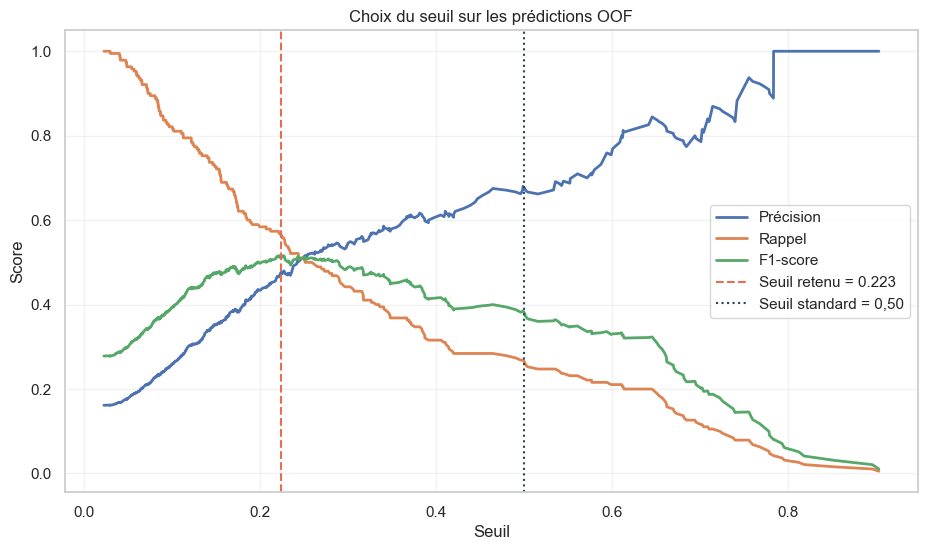

In [63]:
fig, axe = plt.subplots(figsize=(11, 6))
axe.plot(seuils, precisions_utiles, label="Précision", linewidth=2)
axe.plot(seuils, rappels_utiles, label="Rappel", linewidth=2)
axe.plot(seuils, f1_par_seuil, label="F1-score", linewidth=2)
axe.axvline(seuil_optimal, color="#e76f51", linestyle="--", label=f"Seuil retenu = {seuil_optimal:.3f}")
axe.axvline(0.50, color="#264653", linestyle=":", label="Seuil standard = 0,50")
axe.set(title="Choix du seuil sur les prédictions OOF", xlabel="Seuil", ylabel="Score")
axe.legend()
axe.grid(alpha=0.25)
plt.show()


In [64]:
def evaluer_classification(y_true, y_proba, seuil: float) -> dict:
    '''Calcule les métriques et la matrice de confusion pour un seuil donné.'''
    y_pred = (y_proba >= seuil).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Brier score": brier_score_loss(y_true, y_proba),
        "Log Loss": log_loss(y_true, y_proba),
        "Matrice de confusion": confusion_matrix(y_true, y_pred),
    }


comparaison_seuils_oof = {}
for nom_seuil, seuil in {"Seuil 0,50": 0.50, "Seuil optimisé": seuil_optimal}.items():
    comparaison_seuils_oof[nom_seuil] = evaluer_classification(
        y_train, probabilites_oof, seuil
    )

display(
    pd.DataFrame(comparaison_seuils_oof)
    .T.drop(columns="Matrice de confusion")
    .round(4)
)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Brier score,Log Loss
"Seuil 0,50",0.860544,0.675676,0.263158,0.378788,0.79202,0.105811,0.352967
Seuil optimisé,0.829082,0.475771,0.568421,0.517986,0.79202,0.105811,0.352967


<div class="decision-card">
  <b>Justification du seuil.</b> Le seuil retenu maximise le F1 sur les prédictions OOF : il augmente
  le rappel des départs tout en conservant une précision exploitable. Ce compromis est plus pertinent
  que l'accuracy seule sur une cible déséquilibrée.
</div>


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Brier score,Log Loss
"Test — seuil 0,50",0.816327,0.347826,0.170213,0.228571,0.769231,0.122596,0.38898
Test — seuil optimisé,0.802721,0.42029,0.617021,0.5,0.769231,0.122596,0.38898


              precision    recall  f1-score   support

       Resté       0.92      0.84      0.88       247
      Quitté       0.42      0.62      0.50        47

    accuracy                           0.80       294
   macro avg       0.67      0.73      0.69       294
weighted avg       0.84      0.80      0.82       294



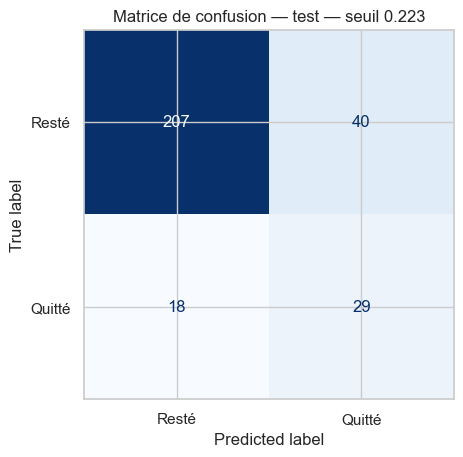

In [65]:
rf_calibre_final = clone(rf_calibre)
rf_calibre_final.fit(X_train, y_train)
probabilites_test = rf_calibre_final.predict_proba(X_test)[:, 1]

resultats_test = {}
for nom_seuil, seuil in {"Test — seuil 0,50": 0.50, "Test — seuil optimisé": seuil_optimal}.items():
    resultats_test[nom_seuil] = evaluer_classification(y_test, probabilites_test, seuil)

tableau_test = pd.DataFrame(resultats_test).T.drop(columns="Matrice de confusion")
display(tableau_test.round(4))

predictions_test_finales = (probabilites_test >= seuil_optimal).astype(int)
print(classification_report(
    y_test,
    predictions_test_finales,
    target_names=["Resté", "Quitté"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test_finales,
    display_labels=["Resté", "Quitté"],
    cmap="Blues",
    colorbar=False,
)
plt.title(f"Matrice de confusion — test — seuil {seuil_optimal:.3f}")
plt.show()


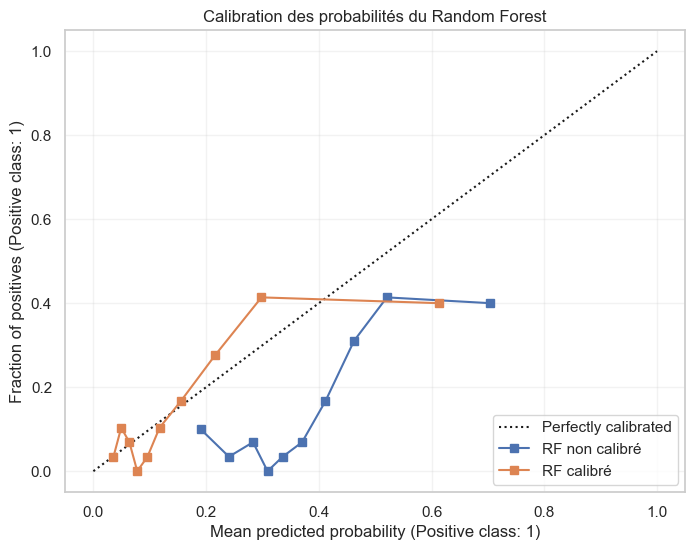

In [66]:
# Contrôle complémentaire de la qualité des probabilités.
rf_non_calibre = clone(meilleur_rf).fit(X_train, y_train)
fig, axe = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_estimator(
    rf_non_calibre, X_test, y_test, n_bins=10,
    strategy="quantile", name="RF non calibré", ax=axe,
)
CalibrationDisplay.from_estimator(
    rf_calibre_final, X_test, y_test, n_bins=10,
    strategy="quantile", name="RF calibré", ax=axe,
)
axe.set_title("Calibration des probabilités du Random Forest")
axe.grid(alpha=0.25)
plt.show()


<div class="section-title"><h2>9 · Importance globale des variables</h2></div>

Trois regards complémentaires sont utilisés :

1. importance native du Random Forest ;
2. importance par permutation sur le test ;
3. valeurs de Shapley avec un **Beeswarm Plot SHAP**.

Le modèle calibré sert aux probabilités finales. Pour SHAP, on entraîne le Random Forest sous-jacent,
dont la structure d'arbres est directement interprétable par `TreeExplainer`.


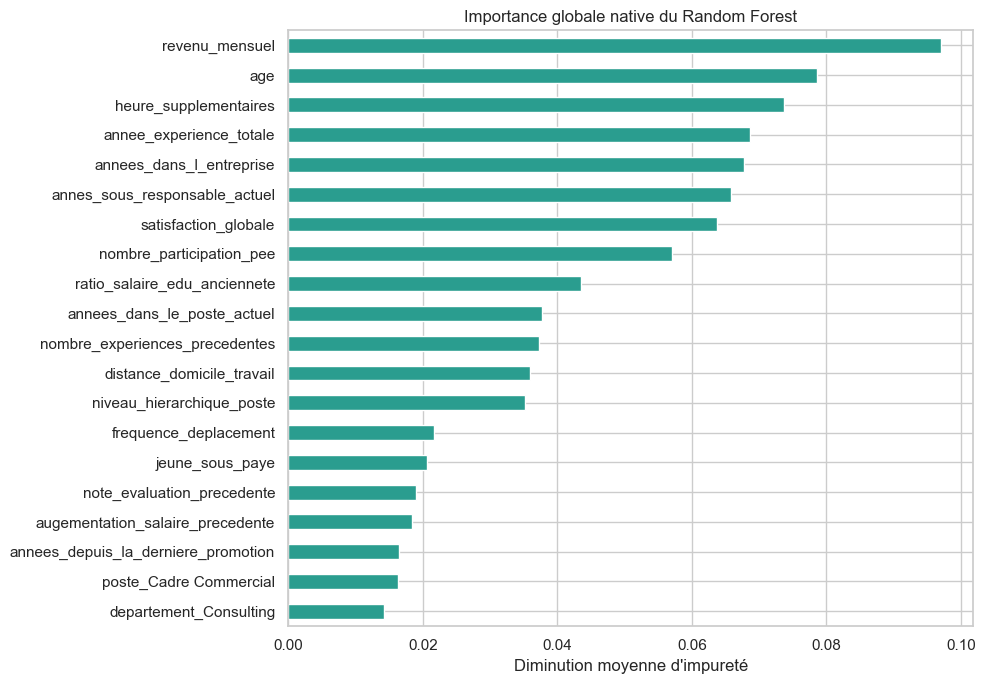

In [67]:
rf_explicable = clone(meilleur_rf).fit(X_train, y_train)

importance_native = (
    pd.Series(rf_explicable.feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
    .head(20)
    .sort_values()
)

importance_native.plot.barh(figsize=(10, 7), color="#2a9d8f")
plt.title("Importance globale native du Random Forest")
plt.xlabel("Diminution moyenne d'impureté")
plt.tight_layout()
plt.show()


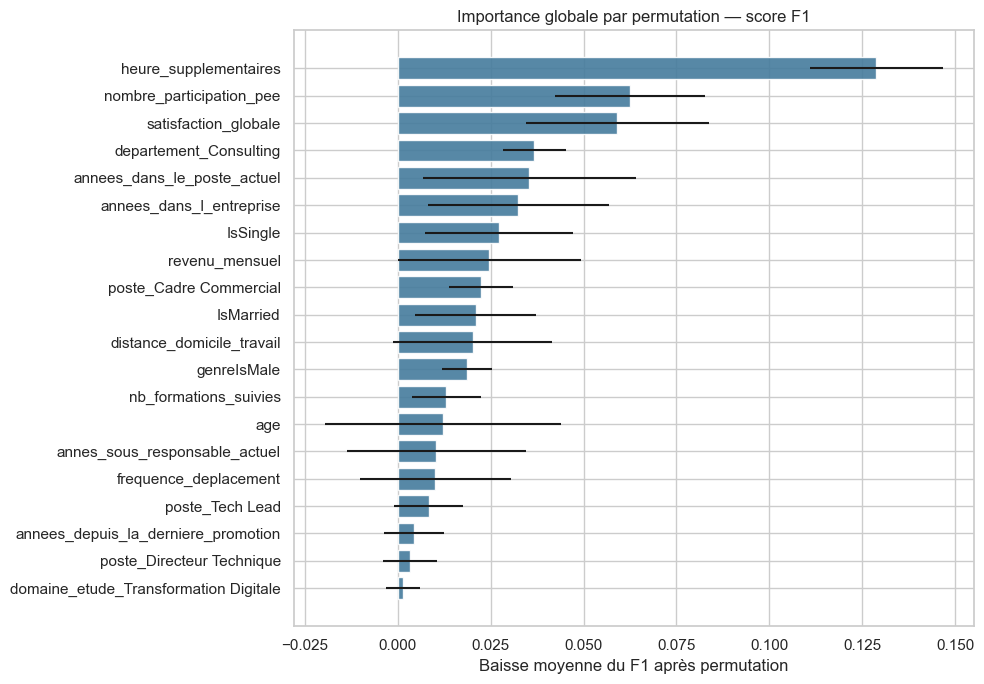

In [68]:
permutation = permutation_importance(
    rf_explicable,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_permutation = (
    pd.DataFrame({
        "feature": X_test.columns,
        "importance_moyenne": permutation.importances_mean,
        "ecart_type": permutation.importances_std,
    })
    .sort_values("importance_moyenne", ascending=False)
    .head(20)
    .sort_values("importance_moyenne")
)

plt.figure(figsize=(10, 7))
plt.barh(
    importance_permutation["feature"],
    importance_permutation["importance_moyenne"],
    xerr=importance_permutation["ecart_type"],
    color="#457b9d",
    alpha=0.9,
)
plt.title("Importance globale par permutation — score F1")
plt.xlabel("Baisse moyenne du F1 après permutation")
plt.tight_layout()
plt.show()


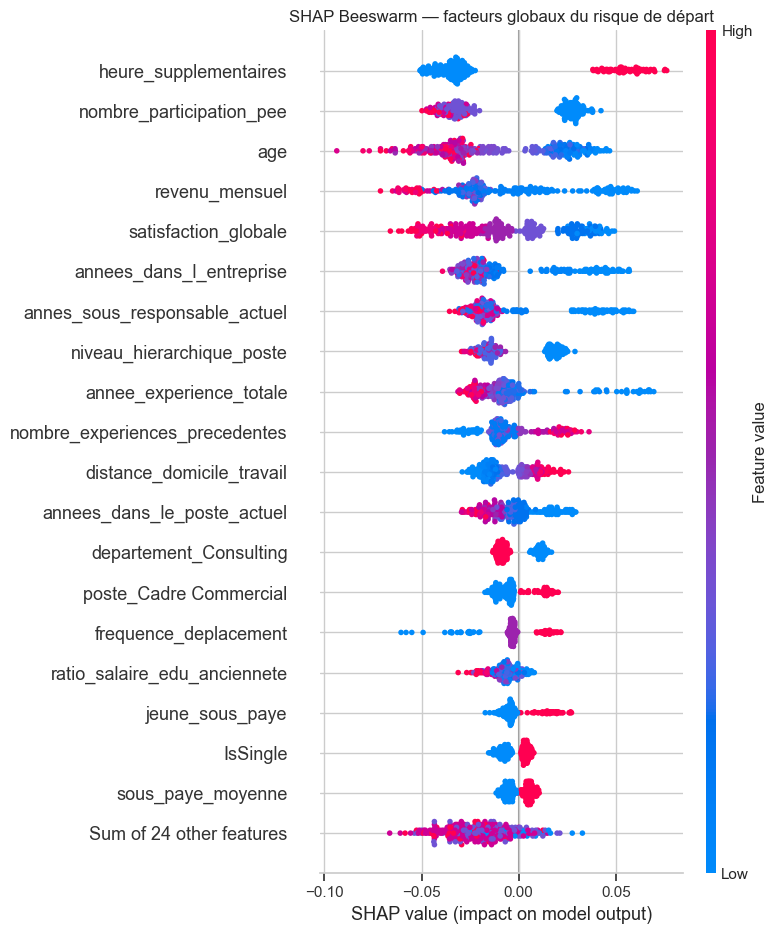

In [69]:
explainer_shap = shap.TreeExplainer(rf_explicable)
shap_brut = explainer_shap(X_test)

# Compatibilité avec les versions de SHAP renvoyant 2D ou 3D en classification.
if shap_brut.values.ndim == 3:
    valeurs_shap_classe_1 = shap_brut.values[:, :, 1]
    valeurs_base_classe_1 = shap_brut.base_values[:, 1]
else:
    valeurs_shap_classe_1 = shap_brut.values
    valeurs_base_classe_1 = shap_brut.base_values

explication_shap = shap.Explanation(
    values=valeurs_shap_classe_1,
    base_values=valeurs_base_classe_1,
    data=X_test.to_numpy(),
    feature_names=X_test.columns.tolist(),
)

shap.plots.beeswarm(explication_shap, max_display=20, show=False)
plt.title("SHAP Beeswarm — facteurs globaux du risque de départ")
plt.tight_layout()
plt.show()


<div class="section-title"><h2>10 · Effets globaux détaillés avec SHAP</h2></div>

Les deux variables les plus importantes au sens de la moyenne des valeurs SHAP absolues
sont représentées par des scatter plots colorés. La couleur met en évidence une interaction
potentielle avec une autre variable.


In [70]:
importance_shap_moyenne = pd.Series(
    np.abs(valeurs_shap_classe_1).mean(axis=0),
    index=X_test.columns,
).sort_values(ascending=False)

deux_features_principales = importance_shap_moyenne.head(2).index.tolist()
display(importance_shap_moyenne.head(20).rename("importance_SHAP_moyenne"))
print("Features retenues pour les scatter plots :", deux_features_principales)


heure_supplementaires             0.040343
nombre_participation_pee          0.031131
age                               0.030654
revenu_mensuel                    0.028211
satisfaction_globale              0.026262
annees_dans_l_entreprise          0.024894
annes_sous_responsable_actuel     0.023023
niveau_hierarchique_poste         0.017477
annee_experience_totale           0.015680
nombre_experiences_precedentes    0.013226
distance_domicile_travail         0.012629
annees_dans_le_poste_actuel       0.011052
departement_Consulting            0.009677
poste_Cadre Commercial            0.008515
frequence_deplacement             0.007963
ratio_salaire_edu_anciennete      0.007518
jeune_sous_paye                   0.007309
IsSingle                          0.005734
sous_paye_moyenne                 0.005681
note_evaluation_precedente        0.005455
Name: importance_SHAP_moyenne, dtype: float64

Features retenues pour les scatter plots : ['heure_supplementaires', 'nombre_participation_pee']


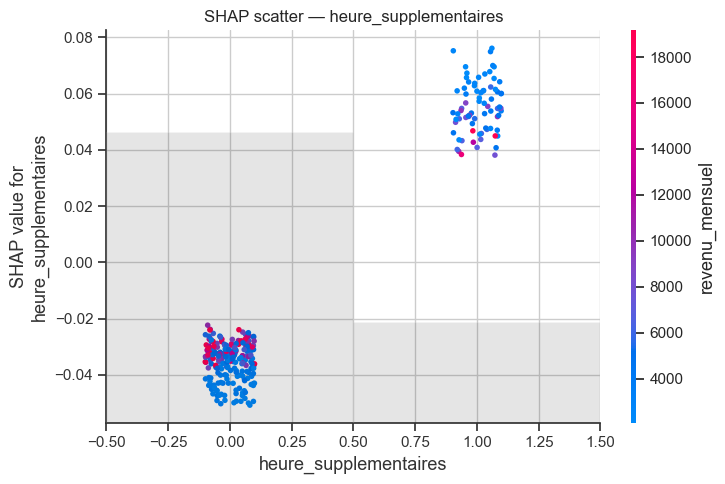

In [71]:
shap.plots.scatter(
    explication_shap[:, deux_features_principales[0]],
    color=explication_shap,
    show=False,
)
plt.title(f"SHAP scatter — {deux_features_principales[0]}")
plt.tight_layout()
plt.show()


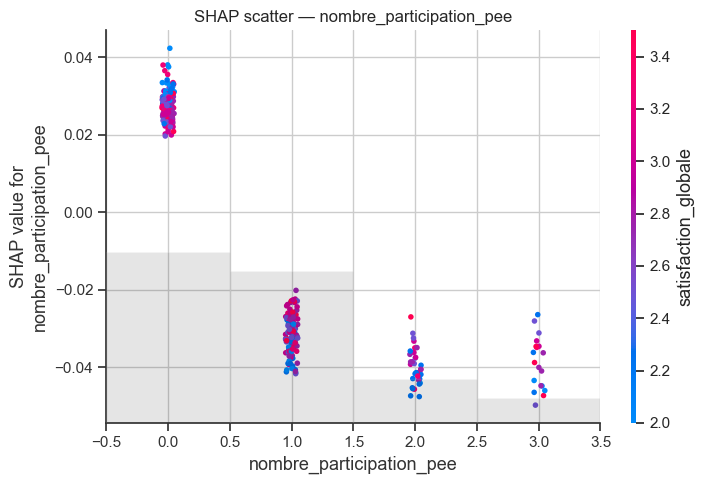

In [72]:
shap.plots.scatter(
    explication_shap[:, deux_features_principales[1]],
    color=explication_shap,
    show=False,
)
plt.title(f"SHAP scatter — {deux_features_principales[1]}")
plt.tight_layout()
plt.show()


<div class="section-title"><h2>11 · Interprétation locale de deux salariés</h2></div>

Les positions `4` et `61` du jeu de test reprennent les deux cas individuels étudiés dans le notebook
initial. Chaque waterfall montre ce qui pousse la prédiction vers le départ ou vers le maintien.
Le tableau associé affiche la valeur réelle de la feature et sa contribution SHAP.


Salarié — position 4 dans X_test — index source 69


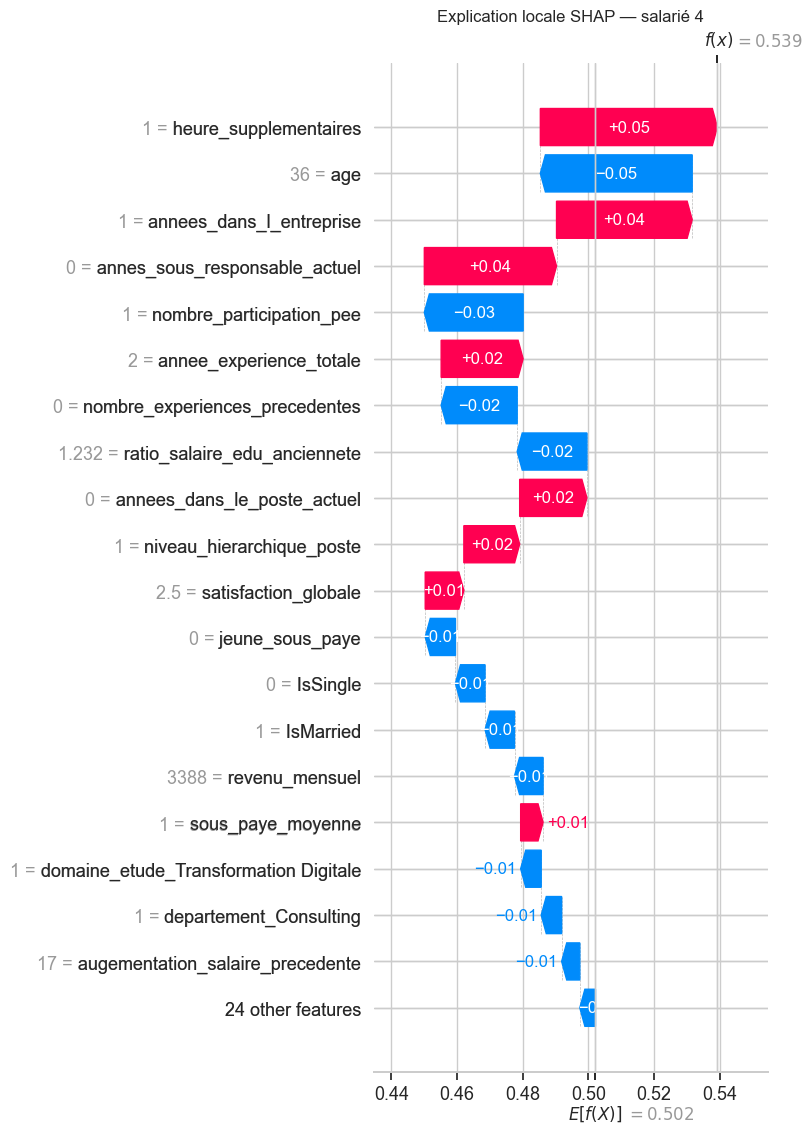

,variable,valeur_feature,valeur_shap,effet
19,heure_supplementaires,1.000000,0.053882,Augmente le risque
9,age,36.000000,-0.046209,Diminue le risque
14,annees_dans_l_entreprise,1.000000,0.041281,Augmente le risque
8,annes_sous_responsable_actuel,0.000000,0.040231,Augmente le risque
0,nombre_participation_pee,1.000000,-0.030072,Diminue le risque
13,annee_experience_totale,2.000000,0.024946,Augmente le risque
11,nombre_experiences_precedentes,0.000000,-0.023135,Diminue le risque
26,ratio_salaire_edu_anciennete,1.231552,-0.021222,Diminue le risque
15,annees_dans_le_poste_actuel,0.000000,0.020465,Augmente le risque
17,niveau_hierarchique_poste,1.000000,0.016985,Augmente le risque


,position_test,index_source,probabilite_calibree_depart,seuil,classe_predite
0,4,69,0.289077,0.223181,1


Salarié — position 61 dans X_test — index source 1210


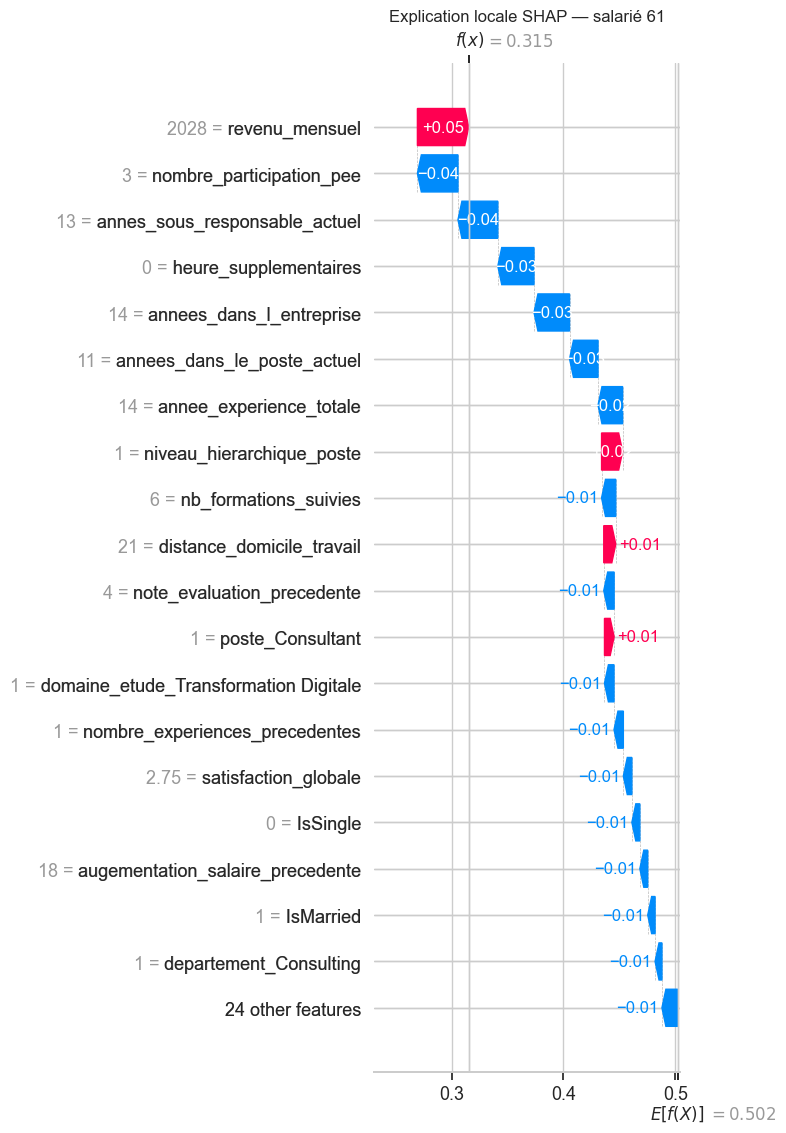

,variable,valeur_feature,valeur_shap,effet
10,revenu_mensuel,2028.00,0.045855,Augmente le risque
0,nombre_participation_pee,3.00,-0.036266,Diminue le risque
8,annes_sous_responsable_actuel,13.00,-0.035600,Diminue le risque
19,heure_supplementaires,0.00,-0.032342,Diminue le risque
14,annees_dans_l_entreprise,14.00,-0.031768,Diminue le risque
15,annees_dans_le_poste_actuel,11.00,-0.025456,Diminue le risque
13,annee_experience_totale,14.00,-0.021980,Diminue le risque
17,niveau_hierarchique_poste,1.00,0.018812,Augmente le risque
1,nb_formations_suivies,6.00,-0.012686,Diminue le risque
3,distance_domicile_travail,21.00,0.010729,Augmente le risque


,position_test,index_source,probabilite_calibree_depart,seuil,classe_predite
0,61,1210,0.072655,0.223181,0


In [73]:
positions_a_expliquer = [4, 61]
if len(X_test) <= max(positions_a_expliquer):
    positions_a_expliquer = [0, len(X_test) - 1]

for position in positions_a_expliquer:
    print("=" * 80)
    print(f"Salarié — position {position} dans X_test — index source {X_test.index[position]}")

    shap.plots.waterfall(
        explication_shap[position],
        max_display=20,
        show=False,
    )
    plt.title(f"Explication locale SHAP — salarié {position}")
    plt.tight_layout()
    plt.show()

    table_locale = pd.DataFrame({
        "variable": X_test.columns,
        "valeur_feature": X_test.iloc[position].to_numpy(),
        "valeur_shap": valeurs_shap_classe_1[position],
    })
    table_locale["effet"] = table_locale["valeur_shap"].apply(
        lambda valeur: "Augmente le risque" if valeur > 0
        else "Diminue le risque" if valeur < 0
        else "Effet nul"
    )
    table_locale["importance_absolue"] = table_locale["valeur_shap"].abs()
    display(
        table_locale
        .sort_values("importance_absolue", ascending=False)
        .drop(columns="importance_absolue")
        .head(20)
    )

    proba_calibree = rf_calibre_final.predict_proba(X_test.iloc[[position]])[0, 1]
    classe_finale = int(proba_calibree >= seuil_optimal)
    display(pd.DataFrame([{
        "position_test": position,
        "index_source": X_test.index[position],
        "probabilite_calibree_depart": proba_calibree,
        "seuil": seuil_optimal,
        "classe_predite": classe_finale,
    }]))


<div class="section-title"><h2>12 · Expérimentations complémentaires</h2></div>

Ces expériences conservent les essais utiles du notebook initial sans brouiller le fil principal :
LightGBM comme autre modèle non linéaire, puis SMOTE appliqué **dans** une pipeline afin que le
sur-échantillonnage reste limité aux folds d'entraînement.


In [74]:
lightgbm = LGBMClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1,
)

scores_lightgbm = cross_validate(
    lightgbm,
    X_train,
    y_train,
    cv=cv_stratifiee,
    scoring=scoring,
    n_jobs=-1,
)

synthese_lightgbm = {
    f"{metrique}_{statistique}": (
        scores_lightgbm[f"test_{metrique}"].mean()
        if statistique == "moyenne"
        else scores_lightgbm[f"test_{metrique}"].std()
    )
    for metrique in scoring
    for statistique in ["moyenne", "ecart_type"]
}
display(pd.DataFrame([synthese_lightgbm], index=["LightGBM"]).round(4))


,accuracy_moyenne,accuracy_ecart_type,precision_moyenne,precision_ecart_type,recall_moyenne,recall_ecart_type,f1_moyenne,f1_ecart_type,roc_auc_moyenne,roc_auc_ecart_type
LightGBM,0.8665,0.0124,0.6204,0.0531,0.4526,0.0421,0.5226,0.0426,0.803,0.0334


In [75]:
pipeline_smote = ImbPipeline([
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

scores_smote = cross_validate(
    pipeline_smote,
    X_train,
    y_train,
    cv=cv_stratifiee,
    scoring=scoring,
    n_jobs=-1,
)

synthese_smote = {
    f"{metrique}_{statistique}": (
        scores_smote[f"test_{metrique}"].mean()
        if statistique == "moyenne"
        else scores_smote[f"test_{metrique}"].std()
    )
    for metrique in scoring
    for statistique in ["moyenne", "ecart_type"]
}
display(pd.DataFrame([synthese_smote], index=["RandomForest + SMOTE"]).round(4))


,accuracy_moyenne,accuracy_ecart_type,precision_moyenne,precision_ecart_type,recall_moyenne,recall_ecart_type,f1_moyenne,f1_ecart_type,roc_auc_moyenne,roc_auc_ecart_type
RandomForest + SMOTE,0.8486,0.0204,0.5375,0.0907,0.4053,0.0993,0.46,0.0936,0.7689,0.0276


<div class="decision-card">
  <b>Choix du modèle final.</b> LightGBM constitue un concurrent performant et le test SMOTE apporte
  un point de comparaison utile. Le Random Forest calibré reste retenu pour le livrable principal :
  il permet un réglage transparent du compromis précision–rappel et une interprétation directe,
  globale comme individuelle, avec SHAP. Ce choix privilégie donc à la fois la capacité prédictive,
  l'explicabilité métier et la maîtrise du seuil de décision.
</div>


In [77]:
from pathlib import Path
import joblib

identifiants_fusionnes = (
    sondage_extract.merge(
        sirh_extract,
        left_on="code_sondage",
        right_on="id_employee",
        how="left",
    )
    .merge(
        eval_extract,
        left_on="code_sondage",
        right_on="eval_number",
        how="inner",
    )[["id_employee"]]
)
assert X.index.equals(identifiants_fusionnes.index)
assert identifiants_fusionnes["id_employee"].notna().all()
assert identifiants_fusionnes["id_employee"].is_unique

records_by_employee_id = {
    str(int(employee_id)): features
    for employee_id, features in zip(
        identifiants_fusionnes["id_employee"],
        X.to_dict(orient="records"),
        strict=True,
    )
}

repertoire_artifact = Path("artifacts")
repertoire_artifact.mkdir(exist_ok=True)
chemin_artifact = repertoire_artifact / "turnover_model.joblib"

joblib.dump(
    {
        "model": rf_calibre_final,
        "threshold": seuil_optimal,
        "feature_names": X_train.columns.tolist(),
        "positive_class": 1,
        "records_by_employee_id": records_by_employee_id,
    },
    chemin_artifact,
)
print(f"Modèle exporté : {chemin_artifact.resolve()}")
print(f"Salariés indexés : {len(records_by_employee_id)}")

Modèle exporté : /Users/samuelgabbai/Documents/workspaceIT/formation_datascientist/Projet4Rendu/artifacts/turnover_model.joblib
Salariés indexés : 1470
